# Student Marks Prediction using Machine Learning

**Algorithm:** Linear Regression  |  **Language:** Python  |  **Tools:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## Problem Statement
Teachers often want to know how a student is likely to perform in the exam. In this project we build a
machine learning model that **predicts a student's exam score** from four factors:
study hours, sleep hours, attendance and previous marks.

## Type of Problem
The exam score is a **number** (for example 34.5), so this is a **supervised learning – regression** problem.

## Dataset
File: `student_exam_scores.csv` (200 students)

| Column | Type | Meaning |
|---|---|---|
| `student_id` | Identifier | Student code (not used for prediction) |
| `hours_studied` | Input feature | Study hours per day |
| `sleep_hours` | Input feature | Sleep hours per day |
| `attendance_percent` | Input feature | Class attendance in percent |
| `previous_scores` | Input feature | Marks in the previous exam |
| `exam_score` | **Target** | Exam score we want to predict |

## Contents of this Notebook
1. **Part 1 – Data Exploration (EDA):** load, clean and understand the data with graphs
2. **Part 2 – Linear Regression and Evaluation:** train/test split, baseline, model, metrics, confusion matrix
3. **Part 3 – Comparing Models:** Linear Regression vs Decision Tree vs KNN, with basic tuning
4. **Part 4 – Clustering (K-Means):** find groups of similar students
5. **Part 5 – Save the Model and Predict for a New Student**
6. **Conclusion, Limitations and Future Scope**

> **Note:** Keep `student_exam_scores.csv` in the same folder as this notebook, then run the cells from top to bottom (**Kernel → Restart & Run All**).

# Part 1: Data Exploration (EDA)
## Step 1: Import the libraries
Libraries are ready-made Python tools. Pandas handles tables, NumPy handles numbers, Matplotlib and Seaborn draw graphs, and Scikit-learn contains the machine learning algorithms.

In [92]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, silhouette_score)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
print("All libraries imported successfully")

All libraries imported successfully


## Step 2: Load the dataset
We read the CSV file with `pd.read_csv()` and look at the first five rows.

In [93]:
try:
    df = pd.read_csv("student_exam_scores.csv")
except FileNotFoundError:
    print("File not found! Keep student_exam_scores.csv in the same folder as this notebook.")
    raise

df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


## Step 3: Understand the data
`shape` gives the number of rows and columns, `info()` gives data types, and `describe()` gives mean, minimum, maximum, etc.

In [94]:
print("Rows and columns:", df.shape)
print()
df.info()

Rows and columns: (200, 6)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    str    
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), str(1)
memory usage: 10.3 KB


In [95]:
df.describe().round(2)

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.00,200.00,200.00,200.00,200.00
mean,6.33,6.62,74.83,66.80,33.96
std,3.23,1.50,14.25,15.66,6.79
min,1.00,4.00,50.30,40.00,17.10
25%,3.50,5.30,62.20,54.00,29.50
50%,6.15,6.70,75.25,67.50,34.05
75%,9.00,8.02,87.43,80.00,38.75
max,12.00,9.00,100.00,95.00,51.30


**Observation:** The dataset has 200 rows and 6 columns, and all numeric columns have proper number data types.
The exam score ranges from about 17 to 51, so in this dataset the exam score is **not out of 100**. We will use the dataset's own scale everywhere in this project.

## Step 4: Data cleaning
Real data can contain missing values, duplicate rows, or impossible values. We check for all of these.

In [96]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64

Duplicate rows: 0


In [97]:
# student_id is only a label (S001, S002 ...), so it cannot help in prediction. We remove it.
df = df.drop(columns=["student_id"])

# Remove duplicates and missing values (none are expected here, but this keeps the code safe)
df = df.drop_duplicates().dropna().reset_index(drop=True)

# Check for impossible values
print("Attendance outside 0-100 :", ((df["attendance_percent"] < 0) | (df["attendance_percent"] > 100)).sum())
print("Negative study/sleep hours:", ((df["hours_studied"] < 0) | (df["sleep_hours"] < 0)).sum())
print("Rows after cleaning       :", len(df))

Attendance outside 0-100 : 0
Negative study/sleep hours: 0
Rows after cleaning       : 200


### Outlier check (IQR method)
An **outlier** is a value that is very far from the others. A value is treated as an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`.

hours_studied        outliers: 0
sleep_hours          outliers: 0
attendance_percent   outliers: 0
previous_scores      outliers: 0
exam_score           outliers: 0


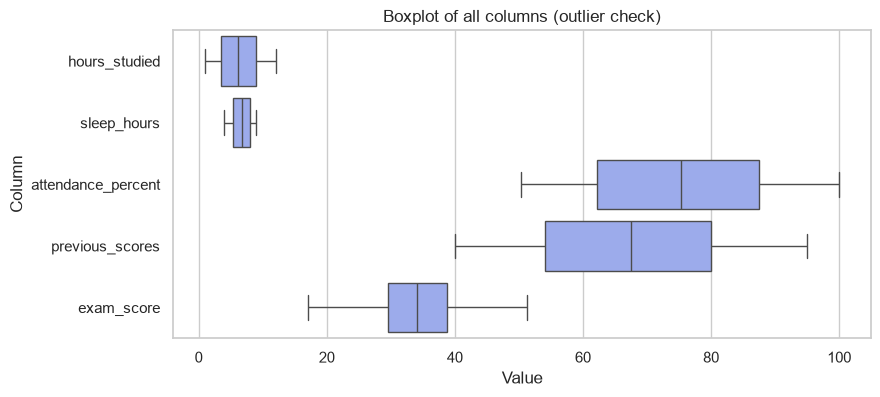

In [98]:
for col in df.columns:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:20s} outliers: {count}")

plt.figure(figsize=(9, 4))
sns.boxplot(data=df, orient="h", color="#8FA3F8")
plt.title("Boxplot of all columns (outlier check)")
plt.xlabel("Value")
plt.ylabel("Column")
plt.show()

**Result:** There are **no missing values, no duplicate rows, no impossible values and no outliers**, so the data is clean and no rows need to be removed.

## Step 5: Feature understanding
* **Features (X)** are the inputs used for prediction.
* **Target (y)** is the value we want to predict.

In [99]:
features = ["hours_studied", "sleep_hours", "attendance_percent", "previous_scores"]
target = "exam_score"

X = df[features]
y = df[target]

print("Input features (X):", features)
print("Target (y)        :", target)
print("Shape of X:", X.shape, "| Shape of y:", y.shape)

Input features (X): ['hours_studied', 'sleep_hours', 'attendance_percent', 'previous_scores']
Target (y)        : exam_score
Shape of X: (200, 4) | Shape of y: (200,)


## Step 6: Exploratory Data Analysis (EDA) with graphs
### Graph 1: Distribution of every column
A histogram shows how the values are spread: tall bars mean many students have values in that range.

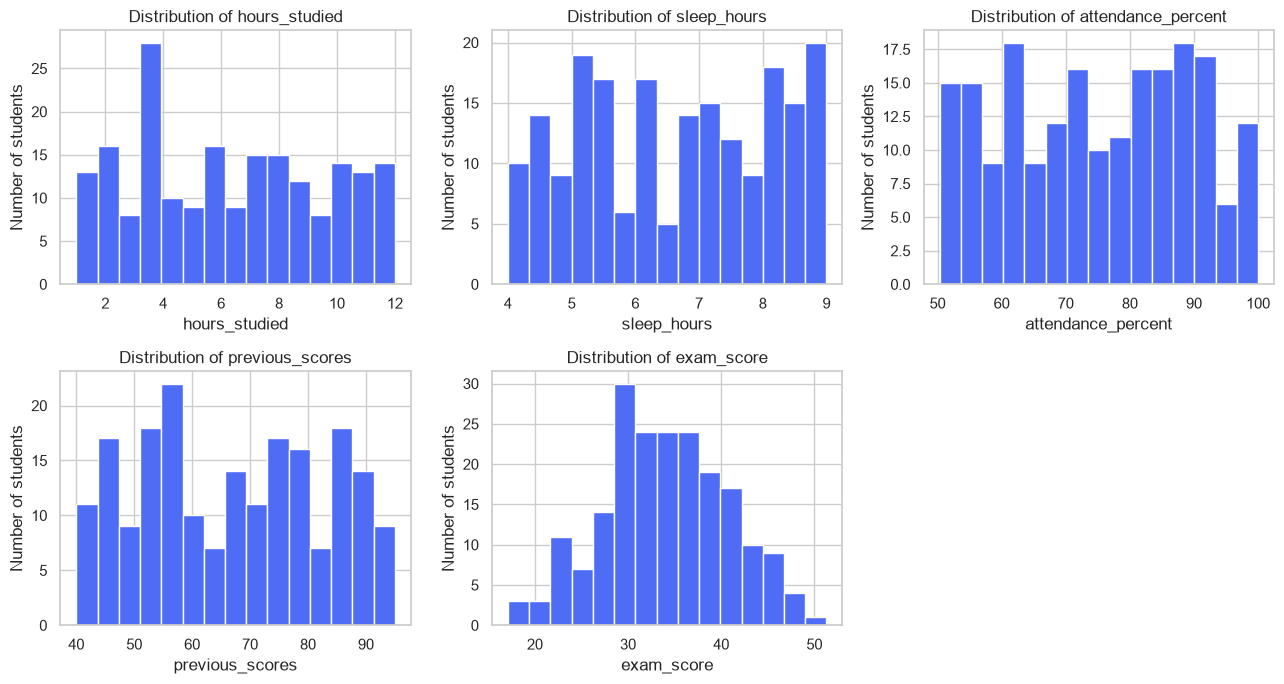

In [100]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=15, color="#4F6CF5", edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")
axes.ravel()[-1].axis("off")   # 5 columns only, so hide the 6th box
plt.tight_layout()
plt.show()

### Graph 2: Each feature vs Exam Score
Each dot is one student. The line shows the general trend. If the line goes up, more of that factor means higher marks.

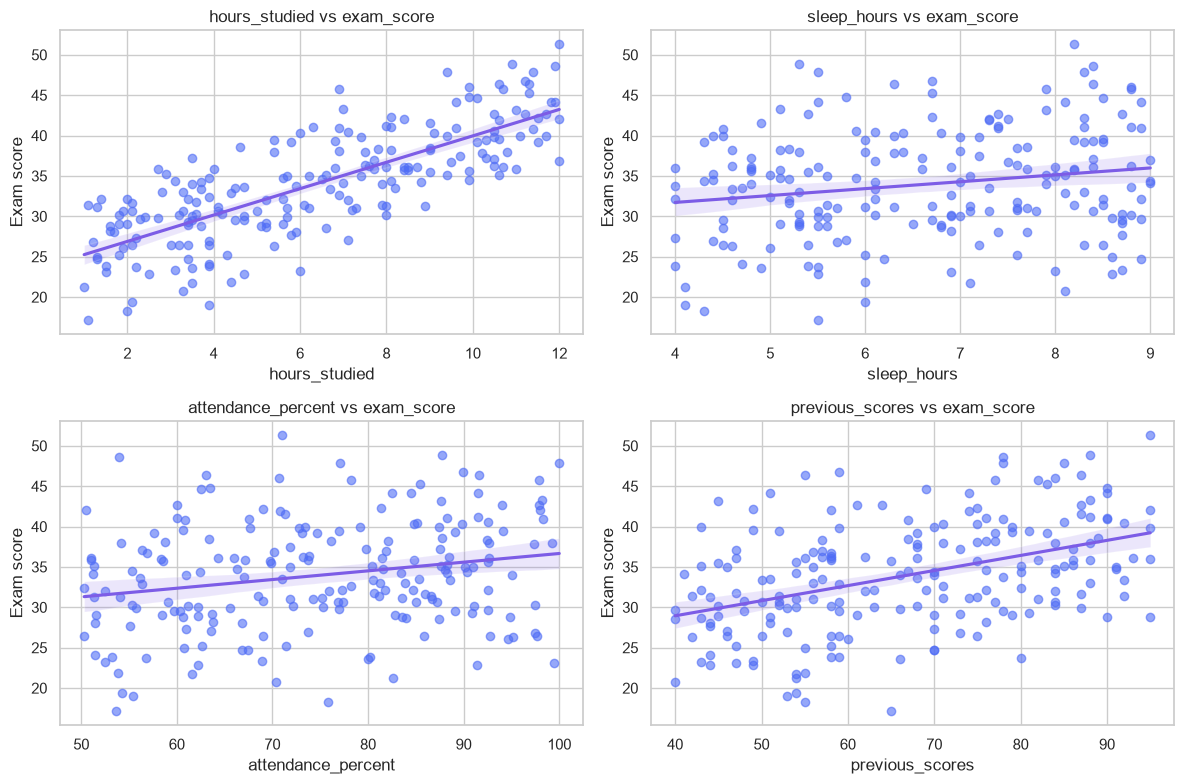

In [101]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), features):
    sns.regplot(data=df, x=col, y=target, ax=ax,
                scatter_kws={"alpha": 0.6, "color": "#4F6CF5"},
                line_kws={"color": "#7C5CE6"})
    ax.set_title(f"{col} vs {target}")
    ax.set_xlabel(col)
    ax.set_ylabel("Exam score")
plt.tight_layout()
plt.show()

### Graph 3: Correlation heatmap
**Correlation (r)** measures how strongly two columns move together. It lies between -1 and +1. Near +1 means "increase together", near 0 means "no straight-line link".

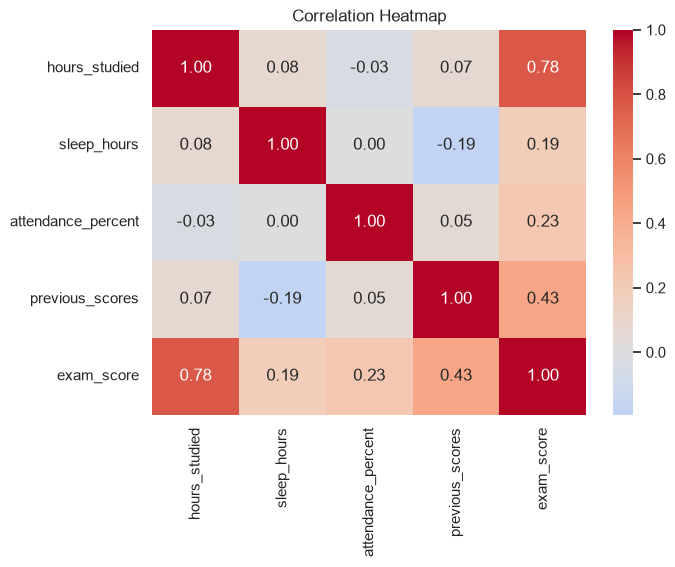

Correlation of each feature with exam_score:
hours_studied         0.777
previous_scores       0.431
attendance_percent    0.226
sleep_hours           0.188
Name: exam_score, dtype: float64


In [102]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation of each feature with exam_score:")
print(df.corr()[target].drop(target).sort_values(ascending=False).round(3))

### Observations from EDA
* **Study hours** has the strongest link with exam score (r about 0.78): students who study more score more.
* **Previous scores** has a moderate link (r about 0.43); **attendance** (about 0.23) and **sleep** (about 0.19) have weaker links.
* The input features are almost **not related to each other** (all below about 0.2). This is good for Linear Regression because each feature adds its own information.
* The scatter plots show roughly **straight-line** patterns, so Linear Regression is a suitable choice.
* Correlation shows a relationship, but it does not prove that one thing *causes* the other.

# Part 2: Linear Regression and Model Evaluation
## Step 7: Train-test split
We cannot test a model on the same data it learned from, just like we cannot set an exam from the exact questions students already practised.
So we divide the data into **80% training data** (to learn) and **20% testing data** (to check). `random_state=42` makes the split the same every time.

In [103]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training students:", X_train.shape[0])
print("Testing students :", X_test.shape[0])

Training students: 160
Testing students : 40


## Step 8: Baseline model
A **baseline** is the simplest possible guess: predict the *average training score* for every student.
Any real model must do better than this, otherwise it is not useful.

In [104]:
baseline_pred = np.full(len(y_test), y_train.mean())

print("Baseline prediction for everyone:", round(y_train.mean(), 2))
print("Baseline MAE :", round(mean_absolute_error(y_test, baseline_pred), 3))
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline_pred)), 3))
print("Baseline R2  :", round(r2_score(y_test, baseline_pred), 3))

Baseline prediction for everyone: 33.85
Baseline MAE : 6.12
Baseline RMSE: 7.303
Baseline R2  : -0.005


## Step 9: Linear Regression model
**Linear Regression** finds the best straight-line relationship between the inputs and the target:

`exam_score = intercept + (w1 x hours_studied) + (w2 x sleep_hours) + (w3 x attendance_percent) + (w4 x previous_scores)`

During training (`fit`), the model finds the best values of the weights (called **coefficients**) so that the prediction error is as small as possible.

In [105]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))
coef_table = pd.DataFrame({"Feature": features, "Coefficient": model.coef_.round(4)})
coef_table

Intercept: -2.205


,Feature,Coefficient
0,hours_studied,1.5493
1,sleep_hours,0.8842
2,attendance_percent,0.1089
3,previous_scores,0.1830


**How to read the coefficients:** a coefficient tells how much the predicted score changes when that feature increases by 1 unit, keeping the other features the same.
For example, the `hours_studied` coefficient shows the extra marks predicted for one extra study hour.
(Features have different scales, so coefficients should not be compared directly as "importance".)

## Step 10: Prediction on test data
Now the model predicts the marks of students it has **never seen** before. We compare actual and predicted marks.

In [106]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred.round(2)
})
comparison["Error"] = (comparison["Actual Marks"] - comparison["Predicted Marks"]).round(2)
comparison.head(10)

,Actual Marks,Predicted Marks,Error
0,28.7,28.89,-0.19
1,34.1,29.68,4.42
2,34.5,35.31,-0.81
3,29.5,31.18,-1.68
4,36.1,39.45,-3.35
5,46.4,41.69,4.71
6,23.9,23.97,-0.07
7,45.3,45.72,-0.42
8,44.8,41.65,3.15
9,31.8,27.48,4.32


## Step 11: Evaluation metrics
| Metric | Meaning | Better when |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the error in marks | Smaller |
| **MSE** (Mean Squared Error) | Average of squared errors (big mistakes count more) | Smaller |
| **RMSE** (Root MSE) | Square root of MSE, in marks | Smaller |
| **R² Score** | Share of the variation in marks explained by the model (1 = perfect, 0 = no better than the average) | Closer to 1 |

R² is **not the same as accuracy**. Accuracy is used for classification problems.

In [107]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Model": ["Baseline (average)", "Linear Regression"],
    "MAE": [mean_absolute_error(y_test, baseline_pred), mae],
    "MSE": [mean_squared_error(y_test, baseline_pred), mse],
    "RMSE": [np.sqrt(mean_squared_error(y_test, baseline_pred)), rmse],
    "R2": [r2_score(y_test, baseline_pred), r2],
}).round(3)
results

,Model,MAE,MSE,RMSE,R2
0,Baseline (average),6.120,53.339,7.303,-0.005
1,Linear Regression,2.311,7.762,2.786,0.854


**Result:** Linear Regression has R² of about **0.85**, so it explains about 85% of the variation in exam marks on unseen students,
and its predictions are off by about **2.3 marks** on average (MAE). The baseline has R² close to 0, so the model is clearly useful.
It is not perfect: some predictions are still wrong, and the test set has only 40 students.

## Step 12: Graphs of model results
### Actual vs Predicted marks
If the model were perfect, all dots would lie on the dashed line.

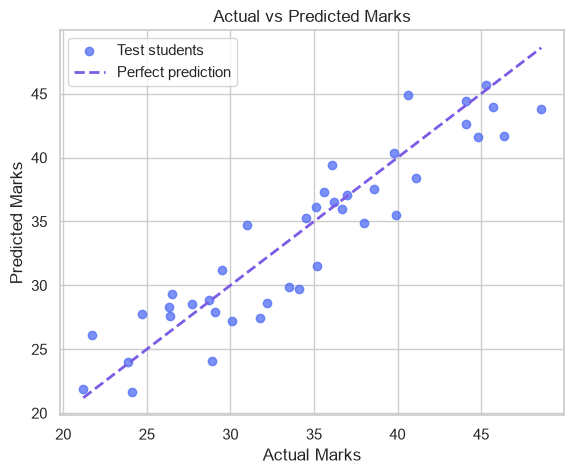

In [108]:
plt.figure(figsize=(6.5, 5))
plt.scatter(y_test, y_pred, color="#4F6CF5", alpha=0.75, label="Test students")
low, high = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "--", color="#7C5CE6", linewidth=2, label="Perfect prediction")
plt.title("Actual vs Predicted Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.legend()
plt.show()

### Distribution of prediction errors (residuals)
Error = Actual - Predicted. A good model has errors centred around zero.

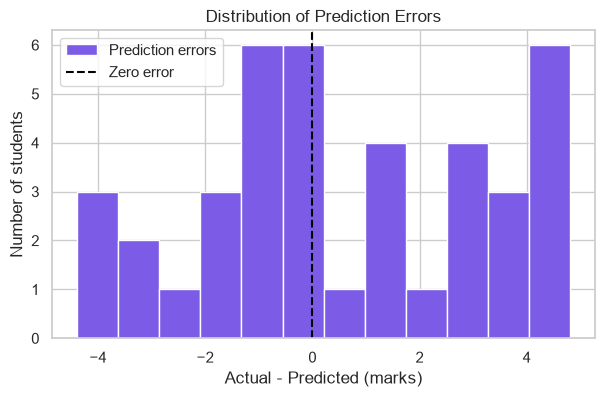

In [109]:
errors = y_test - y_pred

plt.figure(figsize=(7, 4))
plt.hist(errors, bins=12, color="#7C5CE6", edgecolor="white", label="Prediction errors")
plt.axvline(0, color="black", linestyle="--", label="Zero error")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual - Predicted (marks)")
plt.ylabel("Number of students")
plt.legend()
plt.show()

## Step 13: Classification-style evaluation (confusion matrix)
Accuracy, Precision, Recall, F1-score, ROC-AUC and the confusion matrix are **classification** metrics, so they cannot be applied directly to marks.
To also show them, we convert marks into two groups:

* **High performer (1):** score is at or above the median score of the training data
* **Low performer (0):** score is below that median

We then check how well the regression model puts each student in the correct group. This is only an extra view; the main metrics are MAE, MSE, RMSE and R².

In [110]:
threshold = y_train.median()          # taken from training data only
print("Threshold (median training score):", threshold)

y_test_class = (y_test >= threshold).astype(int)    # actual group
y_pred_class = (y_pred >= threshold).astype(int)    # predicted group

print("Accuracy :", round(accuracy_score(y_test_class, y_pred_class), 3))
print("Precision:", round(precision_score(y_test_class, y_pred_class), 3))
print("Recall   :", round(recall_score(y_test_class, y_pred_class), 3))
print("F1-score :", round(f1_score(y_test_class, y_pred_class), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test_class, y_pred), 3))

Threshold (median training score): 33.9
Accuracy : 0.925
Precision: 0.952
Recall   : 0.909
F1-score : 0.93
ROC-AUC  : 0.99


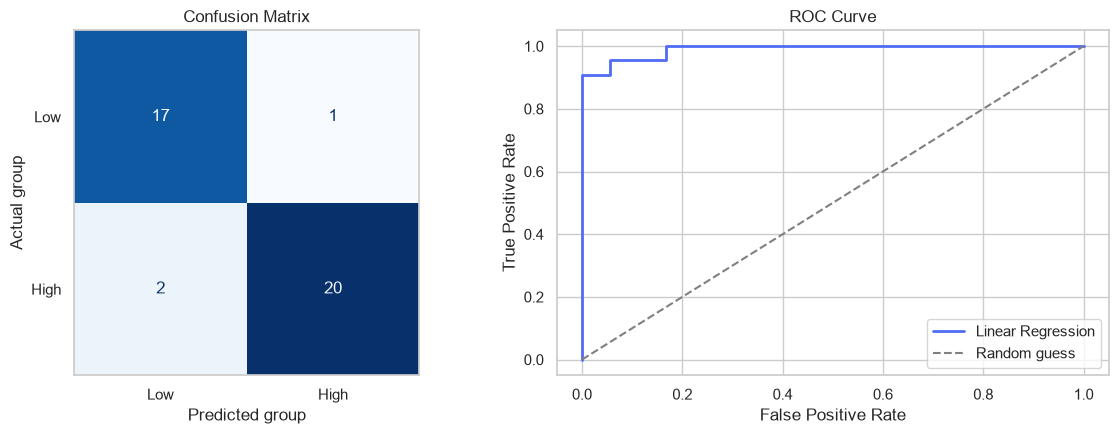

In [111]:
cm = confusion_matrix(y_test_class, y_pred_class)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(cm, display_labels=["Low", "High"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted group")
axes[0].set_ylabel("Actual group")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test_class, y_pred)
axes[1].plot(fpr, tpr, color="#4F6CF5", linewidth=2, label="Linear Regression")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()

**How to read it:** the diagonal boxes of the confusion matrix are correct predictions and the other boxes are mistakes.
Only a few of the 40 test students are placed in the wrong group, and the ROC curve stays close to the top-left corner (ROC-AUC near 1 is better than random guessing at 0.5).

## Step 14: Check that the result is stable (cross-validation)
One train-test split can be lucky or unlucky. In **5-fold cross-validation** the data is split into 5 parts; each part is used once as test data. If the scores are similar every time, the model is reliable.

In [112]:
cv_scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")

print("R2 in each of the 5 folds:", cv_scores.round(3))
print("Average R2:", round(cv_scores.mean(), 3))

R2 in each of the 5 folds: [0.798 0.827 0.855 0.857 0.806]
Average R2: 0.829


The R² values stay close to each other (roughly 0.80 to 0.86), so the model performs consistently and the result is not just luck.

# Part 3: Comparing Different Models
We now compare **three supervised algorithms** on the same train/test data:

1. **Linear Regression:** fits a straight-line relationship
2. **Decision Tree Regressor:** asks a series of yes/no questions (for example "hours studied > 6?")
3. **KNN Regressor:** predicts using the marks of the K most similar students

**Basic hyperparameter tuning:** settings like tree depth (`max_depth`) or number of neighbours (`n_neighbors`) are chosen by trying several values with `GridSearchCV` and 5-fold cross-validation on the *training* data only.
KNN uses distances, so its inputs are first scaled with `StandardScaler`.

In [113]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": GridSearchCV(DecisionTreeRegressor(random_state=42),
                                  {"max_depth": [2, 3, 4, 5, 6, 8]}, cv=5, scoring="r2"),
    "KNN": GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                        {"kneighborsregressor__n_neighbors": [3, 5, 7, 9, 11, 15]}, cv=5, scoring="r2"),
}

rows = []
predictions = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    predictions[name] = pred
    best = m.best_params_ if hasattr(m, "best_params_") else "-"
    rows.append({
        "Model": name,
        "Best settings": best,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

comparison_table = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
comparison_table[["MAE", "RMSE", "R2"]] = comparison_table[["MAE", "RMSE", "R2"]].round(3)
comparison_table

,Model,Best settings,MAE,RMSE,R2
0,Linear Regression,-,2.311,2.786,0.854
1,KNN,{'kneighborsregressor__n_neighbors': 3},3.048,3.695,0.743
2,Decision Tree,{'max_depth': 4},3.737,4.201,0.667


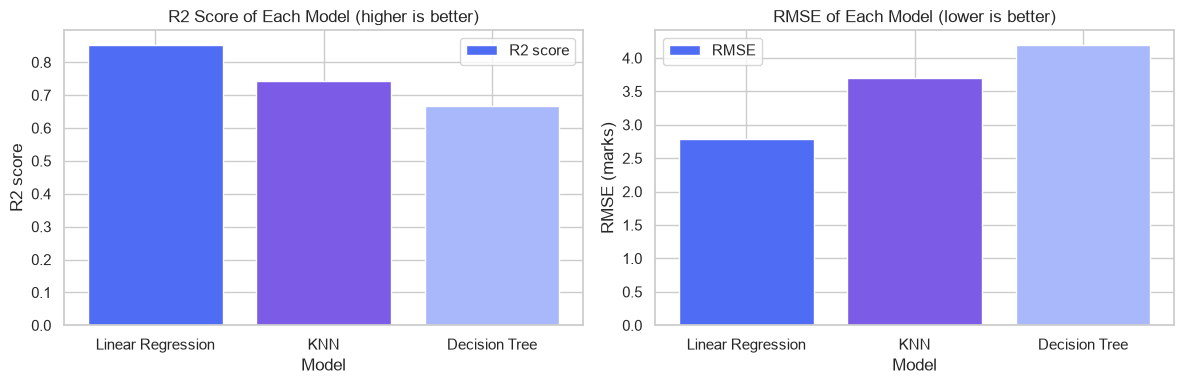

Best model on the test data: Linear Regression


In [114]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(comparison_table["Model"], comparison_table["R2"], color=["#4F6CF5", "#7C5CE6", "#A9B8FA"], label="R2 score")
axes[0].set_title("R2 Score of Each Model (higher is better)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("R2 score")
axes[0].legend()

axes[1].bar(comparison_table["Model"], comparison_table["RMSE"], color=["#4F6CF5", "#7C5CE6", "#A9B8FA"], label="RMSE")
axes[1].set_title("RMSE of Each Model (lower is better)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE (marks)")
axes[1].legend()

plt.tight_layout()
plt.show()

best_model_name = comparison_table.loc[0, "Model"]
print("Best model on the test data:", best_model_name)

### Best model selection
**Linear Regression gives the highest R² and the lowest error** among the three models.
This is reasonable because the EDA showed mostly straight-line relationships, and with only 200 students a simple model is less likely to over-learn the training data than a Decision Tree or KNN.
Linear Regression is also easy to explain, so we use it as the **final model** for the project.

*Note:* the best KNN setting is at the edge of the tried values (3 neighbours), so a wider search could change KNN slightly, but it is unlikely to change the overall conclusion.

# Part 4: Unsupervised Learning – K-Means Clustering
So far we used the exam score to learn (supervised). **Clustering** does not use the target: it looks only at the student habits
(study hours, sleep, attendance, previous marks) and groups similar students together **without being told the groups**.

**K-Means** places K group centres and puts each student in the nearest group. Features are scaled first so that no feature dominates just because its numbers are bigger.

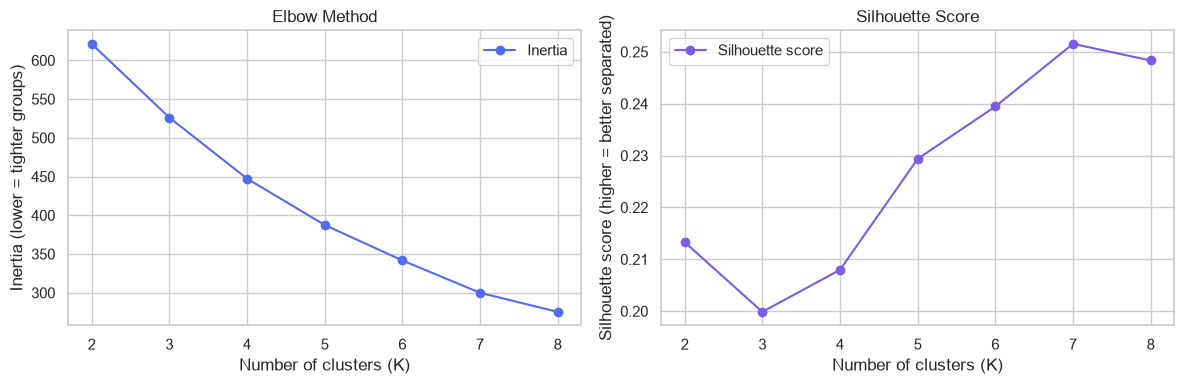

Silhouette scores: {2: 0.213, 3: 0.2, 4: 0.208, 5: 0.229, 6: 0.239, 7: 0.252, 8: 0.248}


In [115]:
scaled_data = StandardScaler().fit_transform(df[features])

# Try K = 2 to 8 and record two measures
inertia, silhouette = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled_data)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(scaled_data, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertia, marker="o", color="#4F6CF5", label="Inertia")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (lower = tighter groups)")
axes[0].legend()

axes[1].plot(list(k_values), silhouette, marker="o", color="#7C5CE6", label="Silhouette score")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Silhouette scores:", {k: round(float(v), 3) for k, v in zip(k_values, silhouette)})

The elbow curve bends gradually and the silhouette scores are low (about 0.2) for every K. This means the students do **not form clearly separated groups**; the groups overlap.
We choose **K = 3** because it gives three easy-to-describe groups for this project, but we should treat the result as a rough grouping, not as sharply defined categories.

In [116]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df_cluster = df.copy()
df_cluster["cluster"] = kmeans.fit_predict(scaled_data)

print("Number of students in each cluster:")
print(df_cluster["cluster"].value_counts().sort_index())
print()
print("Average values for each cluster:")
df_cluster.groupby("cluster").mean().round(2)

Number of students in each cluster:
cluster
0    56
1    77
2    67
Name: count, dtype: int64

Average values for each cluster:


,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
cluster,,,,,
0,5.91,5.15,64.47,67.55,30.87
1,6.75,8.00,71.40,57.06,33.86
2,6.18,6.27,87.43,77.36,36.64


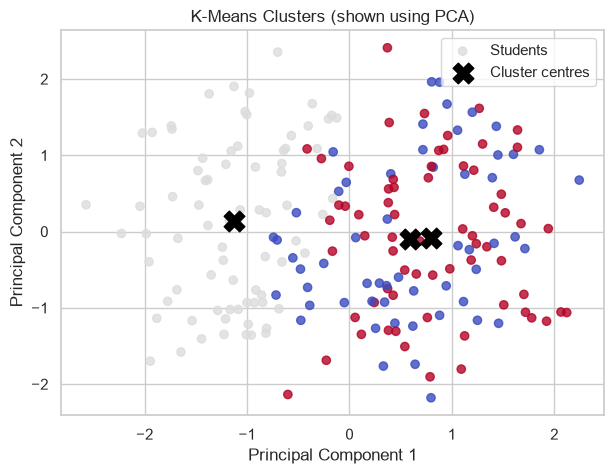

In [117]:
# Reduce 4 features to 2 (PCA) only to be able to draw the clusters on a flat graph
pca = PCA(n_components=2)
points = pca.fit_transform(scaled_data)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(points[:, 0], points[:, 1], c=df_cluster["cluster"], cmap="coolwarm", alpha=0.8, label="Students")
centres = pca.transform(kmeans.cluster_centers_)
plt.scatter(centres[:, 0], centres[:, 1], marker="X", s=220, color="black", label="Cluster centres")
plt.title("K-Means Clusters (shown using PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

### Interpretation of the clusters
Reading the average-values table above (cluster numbers may be ordered differently on another computer, so we describe each group by its habits):

* **Group with the least sleep and lowest attendance** (about 5 hours of sleep, about 64% attendance): it has the **lowest average exam score** (about 31).
* **Group with the most sleep** (about 8 hours) but lower previous marks: its average exam score is **in the middle** (about 34).
* **Group with the highest attendance and highest previous marks** (about 87% attendance, about 77 previous marks): it has the **highest average exam score** (about 37).

**Insight:** the clusters were made without using the exam score, yet they still differ in average exam score. So habits such as attendance, sleep and earlier performance
are linked with final results. Because the groups overlap, this should be used only as a rough guide, for example to find students who may need extra support.

# Part 5: Save the Model and Predict for a New Student
## Step 15: Save the trained model
We save the trained Linear Regression model in a file with **Joblib** so it can be reused later (for example in a web application) without training again.

In [118]:
joblib.dump(model, "linear_regression_model.pkl")
print("Model saved as linear_regression_model.pkl")

loaded_model = joblib.load("linear_regression_model.pkl")
print("Model loaded again successfully")

Model saved as linear_regression_model.pkl
Model loaded again successfully


## Step 16: Predict marks for a new student
The function below checks that the inputs are valid, predicts the marks, and gives a performance level.
Because exam scores in this dataset range between about 17 and 51, the levels are based on how the student compares with the dataset
(lowest 25% = *Needs Improvement*, middle 50% = *Average*, top 25% = *Good*). These labels are only for display and are not part of the regression model.

In [119]:
print("Enter the student's details:")
try:
    study_hours = float(input("Study hours per day: "))
    sleep_hours = float(input("Sleep hours per day: "))
    attendance = float(input("Attendance percentage (0-100): "))
    previous_marks = float(input("Previous marks (0-100): "))

    marks, level = predict_student_marks(study_hours, sleep_hours, attendance, previous_marks)

    print()
    print("Predicted Marks    :", marks)
    print("Performance Level  :", level)
except ValueError as error:
    print("Invalid input:", error)

Enter the student's details:


Study hours per day:  16
Sleep hours per day:  4
Attendance percentage (0-100):  96
Previous marks (0-100):  99



Predicted Marks    : 54.7
Performance Level  : Good


# Conclusion
* We loaded the student dataset, cleaned it (no missing values, duplicates or outliers) and explored it with graphs.
* **Study hours** showed the strongest link with exam score, followed by previous scores.
* A **Linear Regression** model trained on 80% of the data reached an **R² of about 0.85, MAE of about 2.3 marks and RMSE of about 2.8 marks** on unseen students, far better than the baseline of predicting the average.
* Cross-validation gave similar R² values, so the result is stable.
* Linear Regression performed better than the Decision Tree and KNN models, so it was chosen as the final model.
* K-Means clustering showed overlapping but meaningful groups of students whose habits go with different average exam scores.
* The model was saved with Joblib and used to predict marks for new students with input validation.

# Limitations
* The dataset is small (200 students) and has only four input features; many real factors (teaching quality, health, stress, etc.) are missing.
* Linear Regression assumes straight-line relationships.
* The predictions are estimates and must not be treated as guaranteed exam results.
* The exam scores in this dataset are on a limited scale (about 17 to 51), so predictions for very different students may be less reliable.

# Future Scope
* Collect more students and more features (assignment marks, subject difficulty, etc.)
* Try more algorithms such as Random Forest and compare them
* Predict grades (classification) in addition to marks
* Build an early-warning system for students who may need support
* Give personalised study recommendations
* Compare with deep learning on a larger dataset